# EXT 数据集：平均曲线与合理带宽建议

目标：从 `data/bandpass_coupled_line_filter_export/ext/` 自动读取样本，计算平均 `S21/S11`（含波动区间），并根据约束自动给出建议通带。

In [5]:
from __future__ import annotations

from pathlib import Path
import sys
import json

import numpy as np
import matplotlib.pyplot as plt

CWD = Path.cwd().resolve()
if (CWD / 'src').exists():
    REPO_ROOT = CWD
elif (CWD.parent / 'src').exists():
    REPO_ROOT = CWD.parent
else:
    raise RuntimeError(f'Cannot locate repo root from cwd={CWD}')

SRC = REPO_ROOT / 'src'
if str(SRC) in sys.path:
    sys.path.remove(str(SRC))
sys.path.insert(0, str(SRC))

from complex_func import FunctionFromTouchstone

EXT_DIR = REPO_ROOT / 'data' / 'bandpass_coupled_line_filter_export' / 'ext'
EXT_INDEX_PATH = EXT_DIR / 'index.json'

# 带宽设计参数（可改）
S21_PASS_DB = -5.0
S11_PASS_DB = -7.0
TARGET_CENTER_GHZ = 5.55
SEARCH_MIN_GHZ = 4.5
SEARCH_MAX_GHZ = 6.5
USE_MEAN_PLUS_STD_GUARD = True  # True: 使用 mean±std 的保守边界

print('repo root:', REPO_ROOT)
print('ext dir:', EXT_DIR, 'exists=', EXT_DIR.exists())
print('index:', EXT_INDEX_PATH, 'exists=', EXT_INDEX_PATH.exists())

repo root: /home/zhanghf/projects/vector
ext dir: /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext exists= True
index: /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext/index.json exists= True


In [6]:
with EXT_INDEX_PATH.open('r', encoding='utf-8') as f:
    index_payload = json.load(f)
records = index_payload.get('records', {})
if not isinstance(records, dict):
    raise ValueError('index.json has invalid records format')

parser = FunctionFromTouchstone(port_num=2)

freq_ref = None
s21_db_all = []
s11_db_all = []
missing_files = []
skipped_incompatible = 0

for key, rec in records.items():
    filename = rec.get('filename') if isinstance(rec, dict) else None
    if not filename:
        continue

    s2p_path = EXT_DIR / filename
    if not s2p_path.exists():
        missing_files.append(filename)
        continue

    parser.parse(str(s2p_path))
    freqs_hz = np.asarray(parser.freq, dtype=float).reshape(-1)
    s_params = np.asarray(parser.evaluate_all(), dtype=complex)
    if s_params.ndim != 3 or s_params.shape[0] < 2 or s_params.shape[1] < 2:
        skipped_incompatible += 1
        continue

    if freq_ref is None:
        freq_ref = freqs_hz
    elif freqs_hz.shape != freq_ref.shape or not np.allclose(freqs_hz, freq_ref):
        skipped_incompatible += 1
        continue

    s21_db = 20.0 * np.log10(np.maximum(np.abs(s_params[1, 0, :]), 1e-15))
    s11_db = 20.0 * np.log10(np.maximum(np.abs(s_params[0, 0, :]), 1e-15))
    s21_db_all.append(s21_db)
    s11_db_all.append(s11_db)

if freq_ref is None or not s21_db_all:
    raise RuntimeError('No valid touchstone traces loaded from ext dataset')

s21_db_all = np.asarray(s21_db_all, dtype=float)
s11_db_all = np.asarray(s11_db_all, dtype=float)
freq_ghz = freq_ref / 1e9

print('records in index:', len(records))
print('valid traces used:', len(s21_db_all))
print('missing files:', len(missing_files))
print('incompatible traces skipped:', skipped_incompatible)
print('frequency points:', len(freq_ref), 'range GHz=', (float(freq_ghz.min()), float(freq_ghz.max())))

records in index: 184
valid traces used: 184
missing files: 0
incompatible traces skipped: 0
frequency points: 401 range GHz= (3.5, 8.7)


In [7]:
s21_mean = s21_db_all.mean(axis=0)
s21_std = s21_db_all.std(axis=0)
s11_mean = s11_db_all.mean(axis=0)
s11_std = s11_db_all.std(axis=0)

search_mask = (freq_ghz >= SEARCH_MIN_GHZ) & (freq_ghz <= SEARCH_MAX_GHZ)

# ---- 概率型可实现性判定（不是“全满足”）----
# 每个频点上，统计 ext 样本里满足阈值的比例
point_ok = (s21_db_all >= S21_PASS_DB) & (s11_db_all <= S11_PASS_DB)
point_pass_prob = point_ok.mean(axis=0)  # [0,1]

# 候选段：先用均值曲线给一个可行区域种子（避免离谱段）
seed_mask = (s21_mean >= S21_PASS_DB - 1.0) & (s11_mean <= S11_PASS_DB + 1.0) & search_mask
seed_idx = np.where(seed_mask)[0]
if len(seed_idx) == 0:
    # 兜底：仅用搜索区间
    seed_idx = np.where(search_mask)[0]

splits = np.where(np.diff(seed_idx) > 1)[0] + 1
seed_segments = np.split(seed_idx, splits)

# 参数：可实现概率下限 + 最小点数
MIN_PASS_PROB = 0.10
MIN_POINTS = 5

def _all_windows(seg: np.ndarray):
    n = len(seg)
    for i in range(n):
        for j in range(i + MIN_POINTS - 1, n):
            yield seg[i:j+1]

def window_score(win: np.ndarray) -> tuple[float, float, float]:
    f_lo = freq_ghz[win[0]]
    f_hi = freq_ghz[win[-1]]
    bw = f_hi - f_lo
    center = 0.5 * (f_lo + f_hi)
    prob_mean = float(point_pass_prob[win].mean())
    # 排序：先最大可实现概率，再最大带宽，再接近目标中心
    return (prob_mean, bw, -abs(center - TARGET_CENTER_GHZ))

candidates = []
for seg in seed_segments:
    if len(seg) < MIN_POINTS:
        continue
    for win in _all_windows(seg):
        pmin = float(point_pass_prob[win].min())
        if pmin >= MIN_PASS_PROB:
            candidates.append(win)

if not candidates:
    # 若阈值过高，自动降一点
    MIN_PASS_PROB = 0.50
    for seg in seed_segments:
        if len(seg) < MIN_POINTS:
            continue
        for win in _all_windows(seg):
            pmin = float(point_pass_prob[win].min())
            if pmin >= MIN_PASS_PROB:
                candidates.append(win)

if not candidates:
    raise RuntimeError('No likely passband found. Try lower S21/S11 thresholds or wider search range.')

best_seg = max(candidates, key=window_score)
fL = float(freq_ghz[best_seg[0]])
fH = float(freq_ghz[best_seg[-1]])
f0 = 0.5 * (fL + fH)
bw = fH - fL
fbw = bw / f0 if f0 > 0 else np.nan

seg_prob_mean = float(point_pass_prob[best_seg].mean())
seg_prob_min = float(point_pass_prob[best_seg].min())

print('Suggested likely passband (GHz):', (fL, fH))
print('Center f0 (GHz):', f0)
print('Bandwidth BW (GHz):', bw)
print('Fractional BW (FBW):', fbw)
print('Pass probability in segment: mean=', seg_prob_mean, ', min=', seg_prob_min)
print('Constraints used per sample point: S21 >=', S21_PASS_DB, 'dB and S11 <=', S11_PASS_DB, 'dB')
print('Selection rule: maximize (probability, bandwidth, center closeness), with min point probability >=', MIN_PASS_PROB)


Suggested likely passband (GHz): (5.372, 5.424)
Center f0 (GHz): 5.398
Bandwidth BW (GHz): 0.05200000000000049
Fractional BW (FBW): 0.009633197480548443
Pass probability in segment: mean= 0.692391304347826 , min= 0.6902173913043478
Constraints used per sample point: S21 >= -5.0 dB and S11 <= -7.0 dB
Selection rule: maximize (probability, bandwidth, center closeness), with min point probability >= 0.1


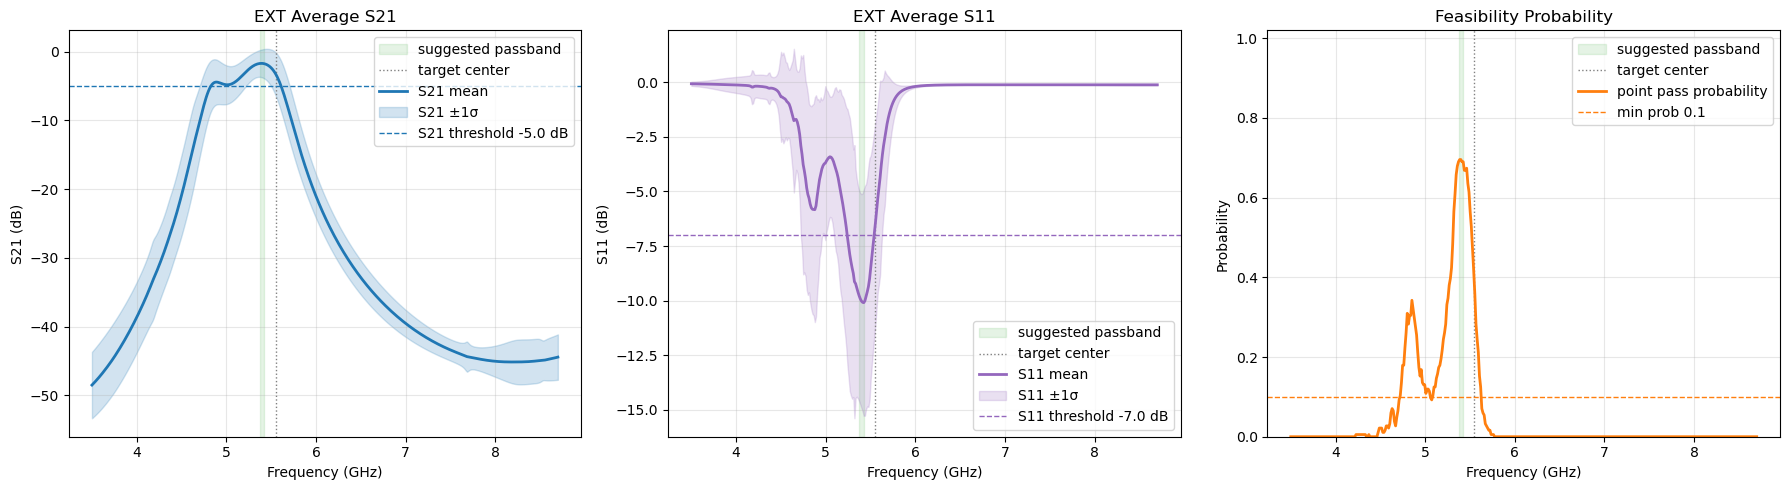

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

for ax in axes:
    ax.axvspan(fL, fH, color='tab:green', alpha=0.12, label='suggested passband')
    ax.axvline(TARGET_CENTER_GHZ, color='gray', linestyle=':', lw=1, label='target center')
    ax.grid(True, alpha=0.3)

axes[0].plot(freq_ghz, s21_mean, color='tab:blue', lw=2, label='S21 mean')
axes[0].fill_between(freq_ghz, s21_mean - s21_std, s21_mean + s21_std, color='tab:blue', alpha=0.20, label='S21 ±1σ')
axes[0].axhline(S21_PASS_DB, color='tab:blue', linestyle='--', lw=1, label=f'S21 threshold {S21_PASS_DB} dB')
axes[0].set_title('EXT Average S21')
axes[0].set_xlabel('Frequency (GHz)')
axes[0].set_ylabel('S21 (dB)')
axes[0].legend(loc='best')

axes[1].plot(freq_ghz, s11_mean, color='tab:purple', lw=2, label='S11 mean')
axes[1].fill_between(freq_ghz, s11_mean - s11_std, s11_mean + s11_std, color='tab:purple', alpha=0.20, label='S11 ±1σ')
axes[1].axhline(S11_PASS_DB, color='tab:purple', linestyle='--', lw=1, label=f'S11 threshold {S11_PASS_DB} dB')
axes[1].set_title('EXT Average S11')
axes[1].set_xlabel('Frequency (GHz)')
axes[1].set_ylabel('S11 (dB)')
axes[1].legend(loc='best')

axes[2].plot(freq_ghz, point_pass_prob, color='tab:orange', lw=2, label='point pass probability')
axes[2].axhline(MIN_PASS_PROB, color='tab:orange', linestyle='--', lw=1, label=f'min prob {MIN_PASS_PROB}')
axes[2].set_title('Feasibility Probability')
axes[2].set_xlabel('Frequency (GHz)')
axes[2].set_ylabel('Probability')
axes[2].set_ylim(0.0, 1.02)
axes[2].legend(loc='best')

plt.tight_layout()
plt.show()
